**Nama:** (Arimbi Deby Setyoningrum)
**NIM:** (24031554186)

**Periode yang dipilih (kombinasi no. 18):** P1 (training) 01-15 Juni 2015 | P2 (testing) 16-31 Juli 2015



# BAGIAN 2.1 


In [ ]:
from neo4j import GraphDatabase

driver = GraphDatabase.driver("neo4j://127.0.0.1:7687", auth=("neo4j", "password"))
driver.verify_connectivity()
print("neo4j tersambung")

neo4j tersambung


In [ ]:
import pandas as pd
df = pd.read_csv("events.csv")
print(df.shape)
df.head()

(2756101, 5)


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


# 2.1 Wrangling dan EDA 
## Rentang periode data

In [ ]:
df["dt"] = pd.to_datetime(df["timestamp"], unit="ms")
print(df["dt"].min(), df["dt"].max())

2015-05-03 03:00:04.384000 2015-09-18 02:59:47.788000


Periode yang dipilih: kombinasi no. 18, P1 (training) 01-15 Juni 2015 dan P2 (testing) 16-31 Juli 2015.

In [ ]:
df["dt"] = pd.to_datetime(df["timestamp"], unit="ms")

def cut(df, start, end):
    return df[(df["dt"] >= start) & (df["dt"] < end)]

p1 = cut(df, "2015-06-01", "2015-06-16")   # 01-15 Juni
p2 = cut(df, "2015-07-16", "2015-08-01")   # 16-31 Juli

cols = ["timestamp", "visitorid", "event", "itemid", "transactionid"]
p1[cols].to_csv("events_p1.csv", index=False)
p2[cols].to_csv("events_p2.csv", index=False)
print("P1:", p1.shape, "| P2:", p2.shape)
print(p1["event"].value_counts())

P1: (300563, 6) | P2: (364206, 6)
event
view           291122
addtocart        7110
transaction      2331
Name: count, dtype: int64


**Penjelasan:**
- Kolom `timestamp` berisi waktu dalam milidetik, jadi diubah dulu ke tanggal dengan `pd.to_datetime(unit="ms")`.
- Data asli mencakup 3 Mei sampai 18 September 2015, jadi kedua periode yang dipilih ada di dalam rentang itu.
- Periode (kombinasi no. 18):
  - **P1 (training): 01-15 Juni 2015** = 300.563 baris (view 291.122, addtocart 7.110, transaction 2.331).
  - **P2 (testing): 16-31 Juli 2015** = 364.206 baris.
- Fungsi `cut()` mengambil baris dari tanggal awal sampai sebelum tanggal akhir, lalu hasilnya disimpan ke `events_p1.csv` dan `events_p2.csv`.
- P1 dimasukkan ke Neo4j untuk "belajar", P2 dipakai sebagai kunci jawaban. P1 harus lebih awal dari P2 supaya model menebak masa depan dari data masa lalu.

## Persiapan: koneksi, constraint, dan fungsi import

In [ ]:
import os
import pandas as pd
import numpy as np
import scipy.sparse as sp
import networkx as nx, matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from tqdm import tqdm
from neo4j import GraphDatabase

URI      = "neo4j://127.0.0.1:7687"
USER     = "neo4j"
PASSWORD = "password"
CSV_PATH = "events_p1.csv"
BATCH    = 10000

driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD), notifications_min_severity="OFF")
driver.verify_connectivity()
print("tersambung")

tersambung


In [ ]:
with driver.session() as session:
    session.run("CREATE CONSTRAINT visitor_unik IF NOT EXISTS "
                "FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_unik IF NOT EXISTS "
                "FOR (i:Item) REQUIRE i.itemId IS UNIQUE")
print("constraint dibuat")

constraint dibuat


In [ ]:
def import_batch(tx, batch):
    query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item    {itemId:    row.itemid})
    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp,
                             transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(query, batch=batch)

## Import P1 ke Neo4j

In [ ]:
with driver.session() as s:
    n = s.run("MATCH ()-[r:VIEWED|ADDED_TO_CART|BOUGHT]->() RETURN count(r) AS n").single()["n"]

if n > 0:
    print(f"Database sudah berisi {n:,} relasi, import dilewati.")
else:
    total_rows   = len(pd.read_csv(CSV_PATH, usecols=["timestamp"]))
    total_chunks = (total_rows // BATCH) + 1
    with driver.session() as session:
        chunks = pd.read_csv(CSV_PATH, chunksize=BATCH)
        for chunk in tqdm(chunks, total=total_chunks, desc="Import P1"):
            chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
            session.execute_write(import_batch, chunk.to_dict(orient="records"))
    print("Import selesai")

Import P1: 100%|██████████| 31/31 [00:48<00:00,  1.55s/it]

Import selesai


## No. 3: Komposisi subgraph

In [ ]:
with driver.session() as s:
    print("JENIS SIMPUL:")
    for r in s.run("MATCH (n) RETURN labels(n)[0] AS jenis, count(n) AS jumlah ORDER BY jumlah DESC"):
        print(f"  {r['jenis']:10s} {r['jumlah']:>10,}")
    print("JENIS RELASI:")
    for r in s.run("MATCH ()-[r]->() RETURN type(r) AS relasi, count(r) AS jumlah ORDER BY jumlah DESC"):
        print(f"  {r['relasi']:15s} {r['jumlah']:>10,}")

JENIS SIMPUL:
  Visitor       160,017
  Item           79,896
JENIS RELASI:
  VIEWED             291,122
  ADDED_TO_CART        7,110
  BOUGHT               2,331


# Hasil:
2 jenis simpul: Visitor = 160,017 dan Item = 79,896.
3 jenis relasi: VIEWED = 291,122, ADDED_TO_CART = 7,110, BOUGHT = 2,331.

# Cypher:
-MATCH (n): mengambil semua simpul
-labels(n)[0]: mengambil nama jenis simpulnya (Visitor atau Item)
-count(n): Menghitung jumlahnya, Neo4j mengelompokkan per jenis 
-Untuk relasi caranya sama, tetapi memakai `MATCH ()-[r]->()` dan `type(r)` untuk nama relasinya

## No. 4: VSM simpul User (matriks User-Item)

In [ ]:
q = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS u, i.itemId AS i,
       sum(CASE type(r) WHEN 'VIEWED' THEN 1
                        WHEN 'ADDED_TO_CART' THEN 3
                        WHEN 'BOUGHT' THEN 5 END) AS w
"""
with driver.session() as s:
    rows = [(r["u"], r["i"], r["w"]) for r in s.run(q)]
d = pd.DataFrame(rows, columns=["visitorid", "itemid", "w"])
print("Pasangan user-item unik:", len(d))

users, uidx = np.unique(d.visitorid.values, return_inverse=True)
items, iidx = np.unique(d.itemid.values,   return_inverse=True)

UI = sp.csr_matrix((d.w.values.astype(float), (uidx, iidx)),
                   shape=(len(users), len(items)))   
IU = UI.T.tocsr()                                    

Pasangan user-item unik: 234959


In [ ]:
def info(nama, M):
    total = M.shape[0] * M.shape[1]
    print(f"{nama}: shape={M.shape} | non-zero={M.nnz:,} | density={M.nnz/total:.8%} "
          f"| memori sparse≈{(M.data.nbytes+M.indices.nbytes+M.indptr.nbytes)/1e6:.1f} MB "
          f"| memori jika dense≈{total*8/1e9:,.0f} GB")

info("User-Item (VSM user)", UI)
info("Item-User (VSM item)", IU)

User-Item (VSM user): shape=(160017, 79896) | non-zero=234,959 | density=0.00183781% | memori sparse≈3.5 MB | memori jika dense≈102 GB
Item-User (VSM item): shape=(79896, 160017) | non-zero=234,959 | density=0.00183781% | memori sparse≈3.1 MB | memori jika dense≈102 GB


# VSM
Matriks user-item: baris = Visitor, kolom = Item, isi = bobot interaksi.

# Karakteristik:
Shape: 160.017 × 79.896.
Non-zero: 234.959 pasangan user-item unik
Density: 0,0018%, artinya matriks sangat sparse(hampir semua isinya 0)
Memori:  sebagai sparse matrix hanya 3,5 MB, tetapi jika dense bisa 102 GB


Item acuan (terpopuler): 5411 | dilihat oleh 928 user
Sampel: 12 user, 34 item, 55 sisi


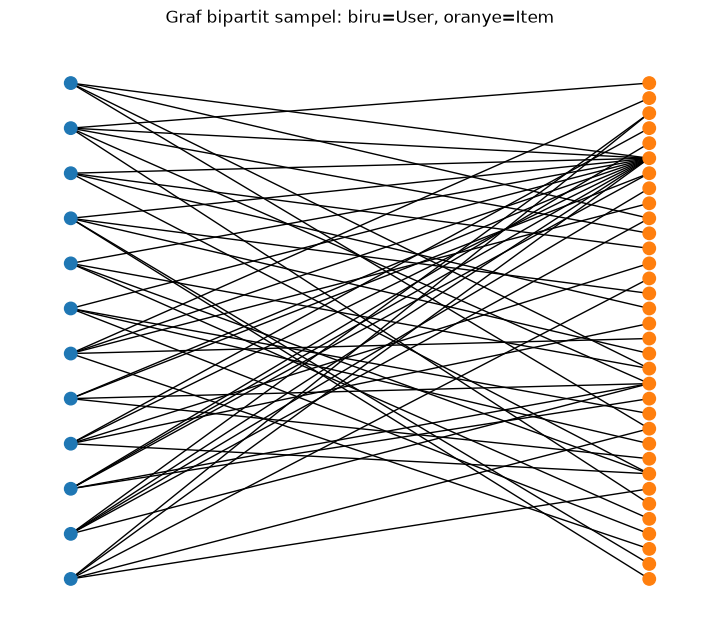

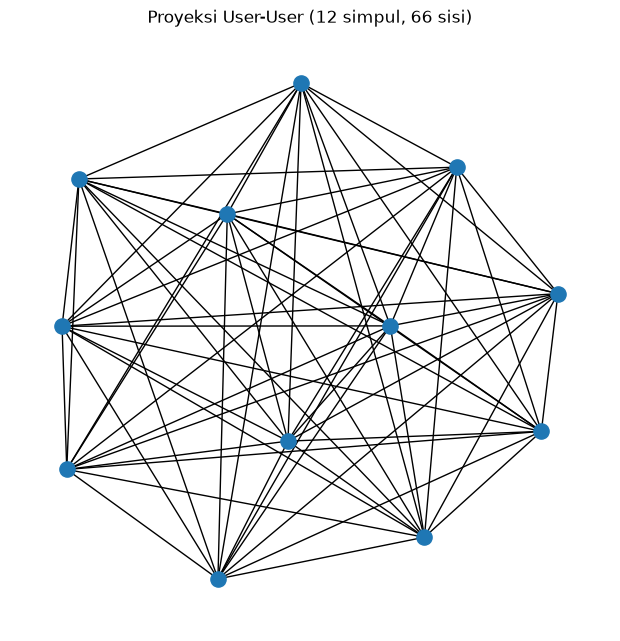

In [ ]:
pop_item = np.diff(IU.indptr)           
ref = int(np.argmax(pop_item))           
REF_ITEM = int(items[ref])
print("Item acuan (terpopuler):", REF_ITEM, "| dilihat oleh", pop_item[ref], "user")

rng = np.random.default_rng(42)
ids = IU[ref].indices
ids = ids[np.diff(UI.indptr)[ids] >= 4]  
samp = rng.choice(ids, size=min(12, len(ids)), replace=False)

G = nx.Graph()
for k in samp:
    for j in set(UI[k].indices[:5]) | {ref}:
        G.add_edge(f"U{users[k]}", f"I{items[j]}")
user_nodes = [n for n in G if n.startswith("U")]
item_nodes = [n for n in G if n.startswith("I")]
print("Sampel:", len(user_nodes), "user,", len(item_nodes), "item,", G.number_of_edges(), "sisi")

#(a)graf bipartit asli
plt.figure(figsize=(7, 6))
pos = nx.bipartite_layout(G, user_nodes)
nx.draw(G, pos, node_size=80, with_labels=False,
        node_color=["tab:blue" if n in user_nodes else "tab:orange" for n in G])
plt.title("Graf bipartit sampel: biru=User, oranye=Item"); plt.show()

#(b)proyeksi user-user  (No. 4)
Pu = nx.bipartite.weighted_projected_graph(G, user_nodes)
plt.figure(figsize=(6, 6))
nx.draw(Pu, nx.spring_layout(Pu, seed=1), node_size=120, node_color="tab:blue", with_labels=False)
plt.title(f"Proyeksi User-User ({Pu.number_of_nodes()} simpul, {Pu.number_of_edges()} sisi)"); plt.show()

# Plot Network: 
dipakai sampel 12 user (acak, seed 42) yang melihat item terpopuler (5411) dan punya minimal 4 item.
Sampel ini berisi 12 user, 34 item, 55 sisi.
# Proyeksi User-user:
12 simpul dan 66 sisi =
**graf lengkap** (12×11/2 = 66). Ini terjadi karena semua user sampel melihat item 5411 yang sama, sehingga semuanya saling terhubung. Hasilnya padat dan kurang informatif

## No. 5: VSM simpul Item (matriks Item-User) dan plot proyeksi Item-Item

Plot Proyeksi Item (No.5)

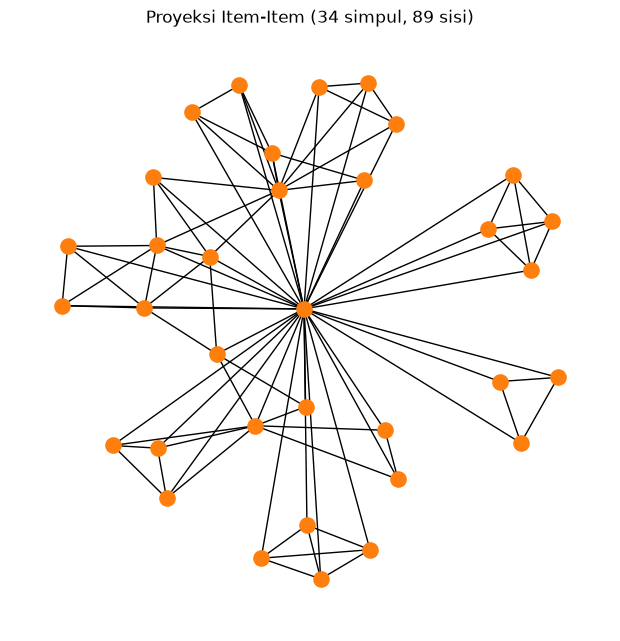

In [ ]:
Pi = nx.bipartite.weighted_projected_graph(G, item_nodes)
plt.figure(figsize=(6, 6))
nx.draw(Pi, nx.spring_layout(Pi, seed=1), node_size=120, node_color="tab:orange", with_labels=False)
plt.title(f"Proyeksi Item-Item ({Pi.number_of_nodes()} simpul, {Pi.number_of_edges()} sisi)"); plt.show()

**Matriks Item-User** adalah transpose dari User-Item; baris = Item, kolom = Visitor. 
Shape: 79.896 × 160.017.
Non-zero dan density: sama dengan User-Item (234.959; 0,0018%), jadi juga sangat sparse.

**Plot proyeksi Item-Item**: 34 simpul dan 89 sisi dari 561 kemungkinan sisi (34×33/2). Jauh lebih jarang daripada proyeksi User-User yang lengkap.
bentuknya seperti bintang: item 5411 jadi pusat (hub), dikelilingi kelompok-kelompok kecil.
Tiap kelompok adalah item yang dilihat oleh satu user yang sama.

## No. 6: Proyeksi mana yang lebih baik?

In [ ]:
U, I = UI.shape
n_per_user = np.diff(UI.indptr)
n_per_item = np.diff(IU.indptr)

print(f"Jumlah user={U:,} | item={I:,} | rasio user/item={U/I:.1f}x")
print(f"Median item per user : {np.median(n_per_user):.0f} | % user hanya 1 item: {(n_per_user==1).mean():.1%}")
print(f"Median user per item : {np.median(n_per_item):.0f} | % item hanya 1 user: {(n_per_item==1).mean():.1%}")
print(f"Matriks similarity user-user : {U*U*8/1e12:.2f} TB (dense)")
print(f"Matriks similarity item-item : {I*I*8/1e9:.0f} GB (dense)")

Jumlah user=160,017 | item=79,896 | rasio user/item=2.0x
Median item per user : 1 | % user hanya 1 item: 81.3%
Median user per item : 1 | % item hanya 1 user: 55.4%
Matriks similarity user-user : 0.20 TB (dense)
Matriks similarity item-item : 51 GB (dense)


# Kesimpulan: 
proyeksi Item-Item lebih baik (efisien dan efektif)

**Efisien:** simpul dan matriks similarity item lebih kecil, jadi hitungannya lebih ringan.

**Efektif:** vektor item lebih padat (lebih sedikit yang hanya punya 1 interaksi), sehingga nilai cosine lebih bermakna. Banyak user hanya melihat 1 item, jadi kemiripan antar user sulit dihitung.

# No. 7: Similarity (cosine) pada proyeksi Item
Hitung similarity (cosine, proyeksi Item)

In [ ]:
IUn = normalize(IU)                      
sims = (IUn @ IUn[ref].T).toarray().ravel()
sims[ref] = -1                           
top = np.argsort(-sims)[:5]

hasil = pd.DataFrame({"itemId": items[top], "similarity": sims[top]})
print("Item acuan:", REF_ITEM)
hasil

Item acuan: 5411


,itemId,similarity
0,33030,0.233859
1,89143,0.209335
2,33956,0.148278
3,459936,0.142188
4,358234,0.090154


**Metode: cosine simlarity pada proyeksi Item** 
Dua item dianggap mirip jika dilihat/dibeli oleh user yang sama, nilai 0 sampai 1
vektor tiap itrm dinormalisasi,  lalu dikalikan dengan vektor item acuan.

**Item acuan: 5411** 

**Top 5 item paling mirip dengan 5411:**
33030, 89143, 33956, 459936, 358234


### No. 7b: Tulis similarity ke graf (relasi SIMILAR_TO)

In [ ]:
rows = [{"a": REF_ITEM, "b": int(items[j]), "score": float(sims[j])} for j in top]
qw = """
UNWIND $rows AS r
MATCH (a:Item {itemId: r.a}), (b:Item {itemId: r.b})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = r.score, s.metode = 'cosine'
"""
with driver.session() as s:
    s.run(qw, rows=rows)
print("Similarity tertulis ke graf")

Similarity tertulis ke graf


Similarity tertulis ke graf sebagai relasi `(Item)-[:SIMILAR_TO {score, metode:'cosine'}]->(Item)`.

`MERGE` dipakai supaya aman dijalankan berulang (tidak membuat relasi ganda).

### No. 7a: Query Cypher top-5 similarity tertinggi

In [ ]:
qr = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN b.itemId AS item, s.score AS similarity
ORDER BY similarity DESC LIMIT 5
"""
with driver.session() as s:
    display(pd.DataFrame([r.data() for r in s.run(qr, ref=REF_ITEM)]))

,item,similarity
0,33030,0.233859
1,89143,0.209335
2,33956,0.148278
3,459936,0.142188
4,358234,0.090154


Query ini membaca kembali 5 similarity tertinggi dari graf: `ORDER BY similarity DESC LIMIT 5`.
Hasilnya sama dengan perhitungan Python. 

## No. 8: Kondisi graf sebelum dan sesudah similarity

SEBELUM:


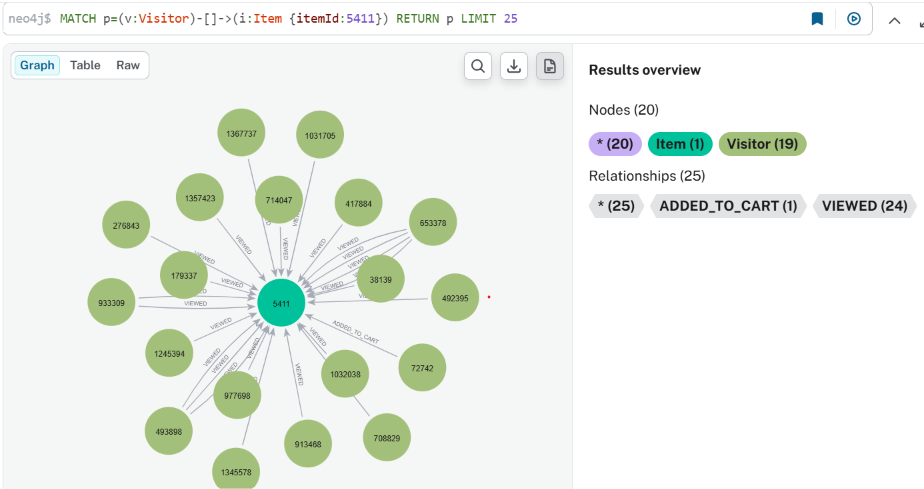

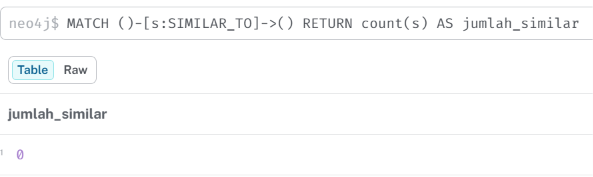

SESUDAH: 

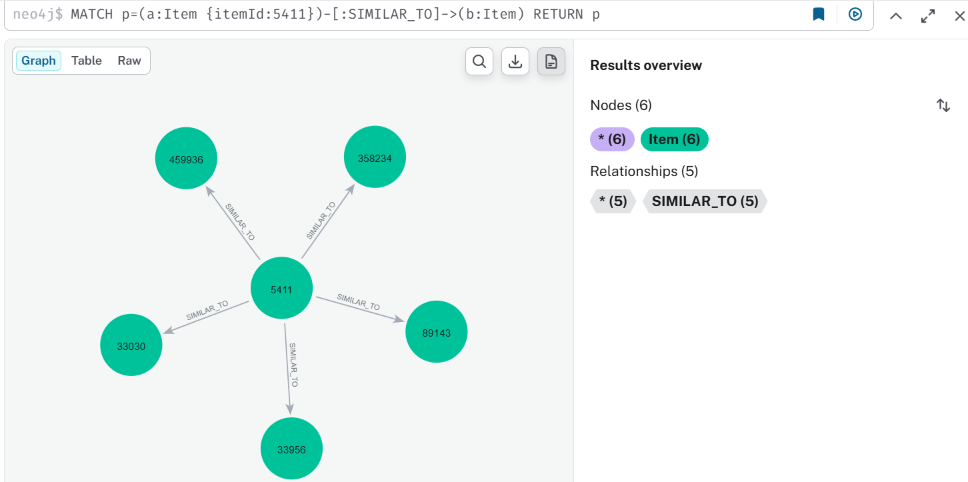

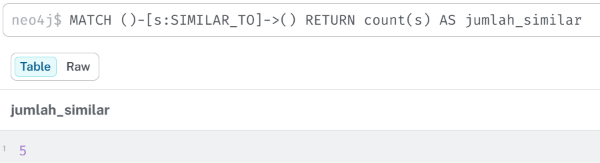

**Query Cypher yang dipakai:**
- Sebelum: `MATCH p=(v:Visitor)-[]->(i:Item {itemId:5411}) RETURN p LIMIT 25` dan `MATCH ()-[s:SIMILAR_TO]->() RETURN count(s)`
- Sesudah: `MATCH p=(a:Item {itemId:5411})-[:SIMILAR_TO]->(b:Item) RETURN p` dan `MATCH ()-[s:SIMILAR_TO]->() RETURN count(s)`

**Penjelasan:**
- **Sebelum:** graf hanya berisi relasi Visitor → Item (di gambar: 19 visitor dengan 24 VIEWED dan 1 ADDED_TO_CART ke item 5411). Jumlah relasi `SIMILAR_TO` = **0**.
- **Sesudah:** muncul **5 relasi SIMILAR_TO** baru antar Item, dari item 5411 ke 5 item termirip, masing-masing membawa `score`. Jumlahnya = **5**.
- Jadi graf kini tidak hanya mencatat perilaku user, tetapi juga kemiripan antar item.

# BAGIAN 2.2

## Pemilihan user acak (reproducible)

In [ ]:
SEED = 42
p2 = pd.read_csv("events_p2.csv")

# Kunci jawaban: item BARU yang disentuh user di P2 (ada di katalog P1, belum pernah dia sentuh di P1)
p2c = p2[p2.itemid.isin(items)][["visitorid", "itemid"]].drop_duplicates()
m = p2c.merge(d[["visitorid", "itemid"]], on=["visitorid", "itemid"], how="left", indicator=True)
p2new = m[m["_merge"] == "left_only"][["visitorid", "itemid"]]

n_per_user = np.diff(UI.indptr)
ok_users = np.isin(users, p2new.visitorid.unique()) & (n_per_user >= 3)
kandidat = np.where(ok_users)[0]
print("Kandidat user:", len(kandidat))

rng = np.random.default_rng(SEED)        # seed tetap = hasil bisa direproduksi
k = int(rng.choice(kandidat))
print("User terpilih: visitorId =", users[k], "| item di P1 =", n_per_user[k])

Kandidat user: 533
User terpilih: visitorId = 113285 | item di P1 = 3


**Proses acak (bisa direproduksi):** `np.random.default_rng(seed=42)` memilih 1 user dari **533 kandidat**.
- Kandidat = user yang punya minimal 3 item di P1 **dan** minimal 1 item **baru** di P2. Tanpa item baru di P2, rekomendasi tidak bisa dinilai benar atau salah.
- Karena seed tetap, hasilnya selalu sama. **User terpilih: visitorId 113285** (3 item di P1).

# No.1a: Skrip KNN

In [ ]:
def recommend(k, K=5, n_seed=20, topn=5):
    row = UI[k]
    order = np.argsort(-row.data)[:n_seed]       
    seed_items = row.indices[order]
    seed_w = dict(zip(row.indices, row.data))
    scores = np.zeros(UI.shape[1])
    for j in seed_items:
        s = (IUn @ IUn[j].T).toarray().ravel()
        s[j] = -1
        nn = np.argpartition(-s, K)[:K]          
        scores[nn] += seed_w[j] * s[nn]
    scores[row.indices] = -np.inf               
    top = np.argsort(-scores)[:topn]
    return [t for t in top if scores[t] > 0]

rec = recommend(k)
rec_items = items[rec]
print("Top-5 rekomendasi:", rec_items.tolist())

Top-5 rekomendasi: [312852, 123745, 284045]


**Cara kerja KNN berbasis item (k = 5)**, sesuai kesimpulan no. 6:
1. Ambil item-item yang pernah disentuh user (urut dari bobot terbesar).
2. Untuk tiap item itu, cari **5 item tetangga terdekat** (cosine).
3. Skor kandidat = jumlah dari (bobot minat user × kemiripan).
4. Item yang sudah pernah disentuh user dibuang, lalu diambil skor tertinggi.

# No.1b:  3 item yang di iklankan (k=5)
3 item yang di iklankan

In [ ]:
print("3 item yang diiklankan (k=5):", rec_items[:3].tolist())

3 item yang diiklankan (k=5): [312852, 123745, 284045]


Item yang diiklankan ke user 113285: **312852, 123745, 284045**.
Hanya 3 (bukan 5) karena user ini hanya punya 3 item di P1, sehingga kandidat yang punya skor positif terbatas.

# No.2: Hit@5 dan NDCG@5

In [ ]:
truth = set(p2new[p2new.visitorid == users[k]].itemid)
rel = [1 if i in truth else 0 for i in rec_items]
rel += [0] * (5 - len(rel))                      

hit5 = int(any(rel))
dcg  = sum(r / np.log2(pos + 2) for pos, r in enumerate(rel))
idcg = sum(1 / np.log2(pos + 2) for pos in range(min(len(truth), 5)))
ndcg5 = dcg / idcg if idcg > 0 else 0.0

print("Kunci jawaban (P2):", sorted(truth)[:10], "| jumlah:", len(truth))
print("Relevansi per posisi:", rel)
print(f"Hit@5  = {hit5}")
print(f"NDCG@5 = {ndcg5:.4f}")

Kunci jawaban (P2): [309273] | jumlah: 1
Relevansi per posisi: [0, 0, 0, 0, 0]
Hit@5  = 0
NDCG@5 = 0.0000


**Arti metrik:**
- **Hit@5:** bernilai 1 jika minimal 1 rekomendasi benar di 5 teratas, selain itu 0.
- **NDCG@5:** tebakan benar di posisi atas bernilai lebih besar (dibagi log2(posisi+1)), lalu dinormalisasi ke 0-1.

**Hasil user 113285:**
- Kunci jawaban (item baru yang diakses di P2) = {309273}.
- Item itu tidak ada di rekomendasi, jadi **Hit@5 = 0** dan **NDCG@5 = 0**.

**Kenapa 0?** Datanya sangat sparse (0,0018%), user ini hanya punya 3 item, dan P1 cuma 2 minggu dengan jarak cukup jauh ke P2. Item baru yang dia akses di P2 sulit ditebak.

# Evaluasi 200 user

In [ ]:
from tqdm.auto import tqdm
rng2 = np.random.default_rng(SEED)
sample_users = rng2.choice(kandidat, size=200, replace=False)

hits, ndcgs = [], []
for kk in tqdm(sample_users):
    rc = items[recommend(int(kk))]
    tr = set(p2new[p2new.visitorid == users[kk]].itemid)
    rl = [1 if i in tr else 0 for i in rc] + [0] * (5 - len(rc))
    hits.append(int(any(rl)))
    dcg = sum(r / np.log2(p + 2) for p, r in enumerate(rl))
    idcg = sum(1 / np.log2(p + 2) for p in range(min(len(tr), 5)))
    ndcgs.append(dcg / idcg if idcg > 0 else 0)

print(f"Rata-rata Hit@5 = {np.mean(hits):.3f} | NDCG@5 = {np.mean(ndcgs):.4f} ({len(sample_users)} user)")

c:\Users\ARIMBY\myvenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 200/200 [00:07<00:00, 25.09it/s]

Rata-rata Hit@5 = 0.020 | NDCG@5 = 0.0040 (200 user)


## Kesimpulan

1. Data P1 (01-15 Juni 2015) berhasil diimpor ke Neo4j: 160.017 Visitor, 79.896 Item, 300.563 relasi.
2. Matriks User-Item dan Item-User sangat sparse (0,0018%), sehingga disimpan sebagai sparse matrix.
3. Proyeksi Item-Item lebih efisien dan efektif dibanding User-User, sehingga dipakai untuk similarity dan KNN.
4. Similarity cosine disimpan kembali ke graf sebagai relasi `SIMILAR_TO`.
5. KNN item-based (k=5) menghasilkan Hit@5 = 0,020 dan NDCG@5 = 0,0040 pada 200 user: rendah.